In [1]:
"""
=============================================================================
Combined SA + QPSO + GT Error Budget Distribution Visualization
=============================================================================
Three figures, each overlaying SA (Simulated Annealing),
QPSO (Quantum Particle Swarm Optimization), and
GT  (Game-Theoretic / Nash equilibrium) on the SAME axes for direct
comparison in a compact paper layout.

Figure 1: Circuit-family violin analysis
Figure 2: Structural property analysis (log-scale scatter)
Figure 3: Gini coefficient analysis
=============================================================================
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from scipy.stats import gaussian_kde, spearmanr
import os
import warnings
warnings.filterwarnings('ignore')

# ── Load data ────────────────────────────────────────────────────────────────
# NOTE: Update these paths to match your Kaggle dataset directories.
df_sa   = pd.read_csv('/kaggle/input/datasets/asifaftabronggon/mqt-sa-1/mqt_benchmark_results_20260126_042753_SA_av.csv')
df_qpso = pd.read_csv('/kaggle/input/datasets/asifaftabronggon/qpso-mqt-1/mqt_benchmark_results_20260413_230035_QPSO_210.csv')
df_gt   = pd.read_csv('/kaggle/input/datasets/asifaftabronggon/mqt-game-theoretic/nash_equilibrium_results_20260215_135842.csv')

os.makedirs('figures', exist_ok=True)

# ── Global approach styling ──────────────────────────────────────────────────
# SA:   circle   markers, blue  palette, solid  lines
# QPSO: triangle markers, red   palette, dashed lines
# GT:   square   markers, green palette, dotted lines
C_SA         = '#2563eb'   # strong blue
C_SA_LIGHT   = '#93c5fd'   # light blue fill
C_QPSO       = '#dc2626'   # strong red
C_QPSO_LIGHT = '#fca5a5'   # light red fill
C_GT         = '#059669'   # strong green (emerald-600)
C_GT_LIGHT   = '#6ee7b7'   # light green fill (emerald-300)

MARKER_SA   = 'o'
MARKER_QPSO = '^'
MARKER_GT   = 's'

LABEL_SA   = 'SA'
LABEL_QPSO = 'QPSO'
LABEL_GT   = 'GT'

In [2]:
# FIGURE 1 — Circuit-Family Violin + Scatter Analysis  (SA vs QPSO)

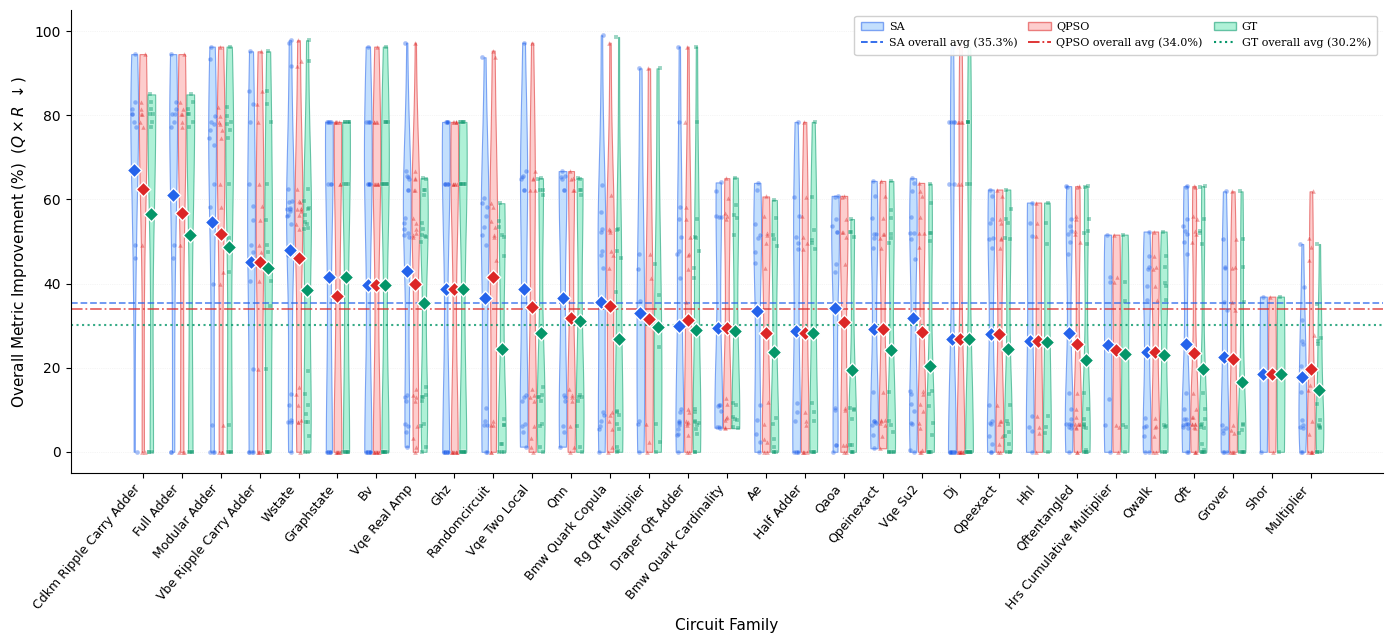


Figure 1 — Circuit-Family Analysis: SA vs QPSO vs GT
Rank Circuit                     SA Mean   SA SD  QPSO Mean   QPSO SD   GT Mean    GT SD   Δ(SA-QP)   Δ(GT-QP)
--------------------------------------------------------------------------------------------------------------------
1    Cdkm Ripple Carry Adder        67.1    28.0       62.4      34.8      56.6     39.1       +4.6       -5.9
2    Full Adder                     61.0    33.4       56.8      38.0      51.4     40.8       +4.2       -5.3
3    Modular Adder                  54.5    35.6       51.7      34.5      48.6     36.9       +2.8       -3.2
4    Vbe Ripple Carry Adder         45.1    32.8       45.1      32.8      43.6     32.7       +0.0       -1.5
5    Wstate                         47.9    30.5       46.0      30.9      38.5     31.0       +1.9       -7.5
6    Graphstate                     41.6    37.8       37.1      38.8      41.6     37.8       +4.5       +4.5
7    Bv                             39.6    37.6    

In [3]:
# Rank circuits by the average of the three approaches' means (fair ordering)
sa_means   = df_sa.groupby('benchmark')['metric_improvement_pct'].mean()
qpso_means = df_qpso.groupby('benchmark')['metric_improvement_pct'].mean()
gt_means   = df_gt.groupby('benchmark')['metric_improvement_pct'].mean()

# Use the intersection of circuit families present in all three datasets so
# every x-tick has three comparable violins.
common_circuits = sa_means.index.intersection(qpso_means.index).intersection(gt_means.index)
combined_rank = ((sa_means.loc[common_circuits] +
                  qpso_means.loc[common_circuits] +
                  gt_means.loc[common_circuits]) / 3.0).sort_values(ascending=False)
sorted_circuits = combined_rank.index.tolist()
n_circuits = len(sorted_circuits)

# Figure setup
fig, ax = plt.subplots(figsize=(14, 6.5))
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif', 'serif'],
    'mathtext.fontset': 'stix',
    'font.size': 9,
})

# Positions: SA left, QPSO center, GT right of each integer tick
offset = 0.22
positions_sa   = np.arange(n_circuits) - offset
positions_qpso = np.arange(n_circuits)
positions_gt   = np.arange(n_circuits) + offset
violin_width   = 0.20

# ── SA violins ───────────────────────────────────────────────────────────────
violin_data_sa = [df_sa[df_sa['benchmark'] == ct]['metric_improvement_pct'].values
                  for ct in sorted_circuits]
parts_sa = ax.violinplot(violin_data_sa, positions=positions_sa, widths=violin_width,
                         showmeans=False, showmedians=False, showextrema=False)
for pc in parts_sa['bodies']:
    pc.set_facecolor(C_SA_LIGHT); pc.set_alpha(0.55)
    pc.set_edgecolor(C_SA);        pc.set_linewidth(0.8)

# ── QPSO violins ────────────────────────────────────────────────────────────
violin_data_qpso = [df_qpso[df_qpso['benchmark'] == ct]['metric_improvement_pct'].values
                    for ct in sorted_circuits]
parts_qpso = ax.violinplot(violin_data_qpso, positions=positions_qpso, widths=violin_width,
                           showmeans=False, showmedians=False, showextrema=False)
for pc in parts_qpso['bodies']:
    pc.set_facecolor(C_QPSO_LIGHT); pc.set_alpha(0.55)
    pc.set_edgecolor(C_QPSO);        pc.set_linewidth(0.8)

# ── GT violins ──────────────────────────────────────────────────────────────
violin_data_gt = [df_gt[df_gt['benchmark'] == ct]['metric_improvement_pct'].values
                  for ct in sorted_circuits]
parts_gt = ax.violinplot(violin_data_gt, positions=positions_gt, widths=violin_width,
                         showmeans=False, showmedians=False, showextrema=False)
for pc in parts_gt['bodies']:
    pc.set_facecolor(C_GT_LIGHT); pc.set_alpha(0.55)
    pc.set_edgecolor(C_GT);        pc.set_linewidth(0.8)

# ── Scatter points with jitter ───────────────────────────────────────────────
np.random.seed(42)
jitter = 0.07
for i, circuit in enumerate(sorted_circuits):
    y_sa = df_sa[df_sa['benchmark'] == circuit]['metric_improvement_pct'].values
    x_jit_sa = np.random.uniform(positions_sa[i] - jitter, positions_sa[i] + jitter, size=len(y_sa))
    ax.scatter(x_jit_sa, y_sa, c=C_SA, s=12, alpha=0.40,
               edgecolors='white', linewidth=0.2, zorder=3, marker=MARKER_SA)

    y_qpso = df_qpso[df_qpso['benchmark'] == circuit]['metric_improvement_pct'].values
    x_jit_qpso = np.random.uniform(positions_qpso[i] - jitter, positions_qpso[i] + jitter, size=len(y_qpso))
    ax.scatter(x_jit_qpso, y_qpso, c=C_QPSO, s=12, alpha=0.40,
               edgecolors='white', linewidth=0.2, zorder=3, marker=MARKER_QPSO)

    y_gt = df_gt[df_gt['benchmark'] == circuit]['metric_improvement_pct'].values
    x_jit_gt = np.random.uniform(positions_gt[i] - jitter, positions_gt[i] + jitter, size=len(y_gt))
    ax.scatter(x_jit_gt, y_gt, c=C_GT, s=12, alpha=0.40,
               edgecolors='white', linewidth=0.2, zorder=3, marker=MARKER_GT)

# ── Mean markers ─────────────────────────────────────────────────────────────
means_sa   = [df_sa[df_sa['benchmark']   == ct]['metric_improvement_pct'].mean() for ct in sorted_circuits]
means_qpso = [df_qpso[df_qpso['benchmark'] == ct]['metric_improvement_pct'].mean() for ct in sorted_circuits]
means_gt   = [df_gt[df_gt['benchmark']   == ct]['metric_improvement_pct'].mean() for ct in sorted_circuits]

ax.scatter(positions_sa,   means_sa,   marker='D', s=55, c=C_SA,
           edgecolors='white', linewidth=1.0, zorder=10, label=f'{LABEL_SA} mean')
ax.scatter(positions_qpso, means_qpso, marker='D', s=55, c=C_QPSO,
           edgecolors='white', linewidth=1.0, zorder=10, label=f'{LABEL_QPSO} mean')
ax.scatter(positions_gt,   means_gt,   marker='D', s=55, c=C_GT,
           edgecolors='white', linewidth=1.0, zorder=10, label=f'{LABEL_GT} mean')

# ── Overall mean reference lines ─────────────────────────────────────────────
overall_mean_sa   = df_sa['metric_improvement_pct'].mean()
overall_mean_qpso = df_qpso['metric_improvement_pct'].mean()
overall_mean_gt   = df_gt['metric_improvement_pct'].mean()

ax.axhline(y=overall_mean_sa,   color=C_SA,   linestyle='--', linewidth=1.3, alpha=0.7)
ax.axhline(y=overall_mean_qpso, color=C_QPSO, linestyle='-.', linewidth=1.3, alpha=0.7)
ax.axhline(y=overall_mean_gt,   color=C_GT,   linestyle=':',  linewidth=1.5, alpha=0.8)

# ── Axes formatting ──────────────────────────────────────────────────────────
labels = [c.replace('_', ' ').title() for c in sorted_circuits]
ax.set_xticks(range(n_circuits))
ax.set_xticklabels(labels, rotation=50, ha='right', fontsize=9)

ax.set_ylabel(r'Overall Metric Improvement (%)  ($Q \times R$ $\downarrow$)', fontsize=11)
ax.set_xlabel('Circuit Family', fontsize=11)

ax.set_ylim(-5, 105)
ax.grid(axis='y', alpha=0.25, linestyle=':', linewidth=0.5)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.8)
ax.spines['bottom'].set_linewidth(0.8)

# ── Legend ────────────────────────────────────────────────────────────────────
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

# Reordered to group SA together, QPSO together, and GT together
legend_elements = [
    # SA Group
    Patch(facecolor=C_SA_LIGHT, edgecolor=C_SA, alpha=0.55, label=f'{LABEL_SA}'),
    Line2D([0], [0], color=C_SA, linestyle='--', linewidth=1.3, label=f'{LABEL_SA} overall avg ({overall_mean_sa:.1f}%)'),
    
    # QPSO Group
    Patch(facecolor=C_QPSO_LIGHT, edgecolor=C_QPSO, alpha=0.55, label=f'{LABEL_QPSO}'),
    Line2D([0], [0], color=C_QPSO, linestyle='-.', linewidth=1.3, label=f'{LABEL_QPSO} overall avg ({overall_mean_qpso:.1f}%)'),
    
    # GT Group
    Patch(facecolor=C_GT_LIGHT, edgecolor=C_GT, alpha=0.55, label=f'{LABEL_GT}'),
    Line2D([0], [0], color=C_GT, linestyle=':', linewidth=1.5, label=f'{LABEL_GT} overall avg ({overall_mean_gt:.1f}%)'),
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=8,
          framealpha=0.92, ncol=3, columnspacing=1.0,
          handletextpad=0.5, borderpad=0.6)

plt.tight_layout()
plt.savefig('figures/fig1_circuit_family_SA_vs_QPSO_vs_GT.pdf', bbox_inches='tight', facecolor='white')
plt.savefig('figures/fig1_circuit_family_SA_vs_QPSO_vs_GT.png', dpi=1200, bbox_inches='tight', facecolor='white')
plt.show()

# ── Summary statistics ───────────────────────────────────────────────────────
print("\n" + "="*116)
print("Figure 1 — Circuit-Family Analysis: SA vs QPSO vs GT")
print("="*116)
print(f"{'Rank':<5}{'Circuit':<26}"
      f"{'SA Mean':>9}{'SA SD':>8}"
      f"{'QPSO Mean':>11}{'QPSO SD':>10}"
      f"{'GT Mean':>10}{'GT SD':>9}"
      f"{'Δ(SA-QP)':>11}{'Δ(GT-QP)':>11}")
print("-"*116)
for i, ct in enumerate(sorted_circuits, 1):
    sa_d = df_sa[df_sa['benchmark']==ct]['metric_improvement_pct']
    qp_d = df_qpso[df_qpso['benchmark']==ct]['metric_improvement_pct']
    gt_d = df_gt[df_gt['benchmark']==ct]['metric_improvement_pct']
    d1 = sa_d.mean() - qp_d.mean()
    d2 = gt_d.mean() - qp_d.mean()
    print(f"{i:<5}{ct.replace('_',' ').title():<26}"
          f"{sa_d.mean():>9.1f}{sa_d.std():>8.1f}"
          f"{qp_d.mean():>11.1f}{qp_d.std():>10.1f}"
          f"{gt_d.mean():>10.1f}{gt_d.std():>9.1f}"
          f"{d1:>+11.1f}{d2:>+11.1f}")
print("="*116)
print(f"{'':5}{'Overall':<26}"
      f"{overall_mean_sa:>9.1f}{df_sa['metric_improvement_pct'].std():>8.1f}"
      f"{overall_mean_qpso:>11.1f}{df_qpso['metric_improvement_pct'].std():>10.1f}"
      f"{overall_mean_gt:>10.1f}{df_gt['metric_improvement_pct'].std():>9.1f}"
      f"{overall_mean_sa - overall_mean_qpso:>+11.1f}"
      f"{overall_mean_gt - overall_mean_qpso:>+11.1f}")

In [4]:
# FIGURE 2 — Structural Property Analysis  (SA vs QPSO)

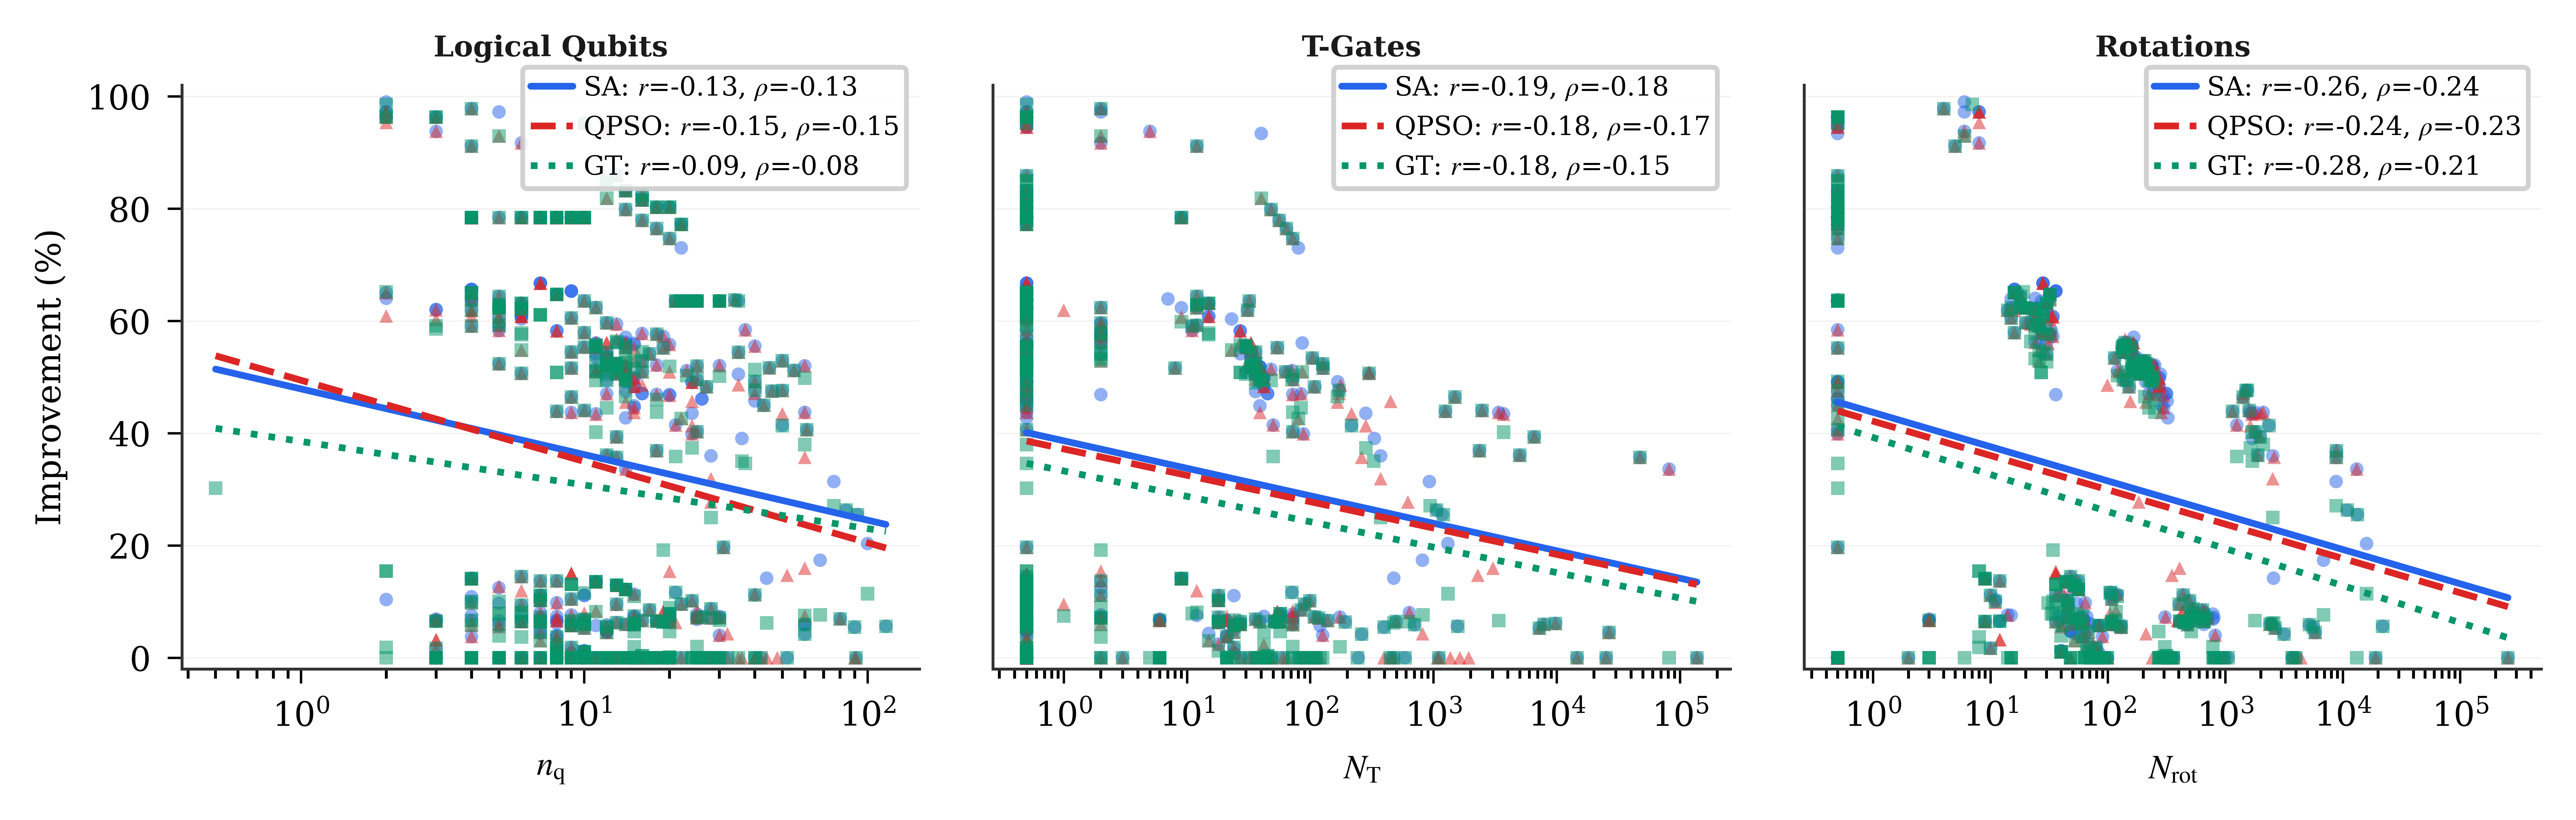


Figure 2 — Structural Properties: SA vs QPSO vs GT (log₁₀-transformed)
Feature             Approach   Pearson r    Spearman ρ    p(Pearson)   p(Spearman)
----------------------------------------------------------------------------------------------
  Logical Qubits    SA          -0.129        -0.128      7.11e-03      7.83e-03
  Logical Qubits    QPSO        -0.152        -0.146      1.50e-03      2.36e-03
  Logical Qubits    GT          -0.088        -0.084      6.84e-02      8.00e-02

  T-Gates           SA          -0.194        -0.184      4.97e-05      1.13e-04
  T-Gates           QPSO        -0.184        -0.174      1.17e-04      2.68e-04
  T-Gates           GT          -0.179        -0.152      1.71e-04      1.51e-03

  Rotations         SA          -0.258        -0.240      4.99e-08      4.23e-07
  Rotations         QPSO        -0.245        -0.226      2.49e-07      2.12e-06
  Rotations         GT          -0.280        -0.209      2.85e-09      1.12e-05



In [5]:
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif', 'serif'],
    'mathtext.fontset': 'stix',
    'font.size': 8,
    'axes.titlesize': 9,
    'axes.labelsize': 8,
    'xtick.labelsize': 7,
    'ytick.labelsize': 7,
    'figure.dpi': 1200,
    'savefig.dpi': 1200,
    'axes.linewidth': 0.6,
    'axes.edgecolor': '#333333',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'ytick.right': False,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

struct_features = [
    ('logical_qubits', 'Logical Qubits',   r'$n_{\mathrm{q}}$'),
    ('t_gates',        'T-Gates',          r'$N_{\mathrm{T}}$'),
    ('rotations',      'Rotations',        r'$N_{\mathrm{rot}}$'),
]

fig, axes = plt.subplots(1, 3, figsize=(7.5, 2.6))
fig.subplots_adjust(wspace=0.10, left=0.07, right=0.98, top=0.85, bottom=0.20)

for idx, (col, title, xlabel) in enumerate(struct_features):
    ax = axes[idx]
    ax.tick_params(axis='both', which='both', top=False, right=False)

    # SHARED log-x range from all three datasets for this feature
    x_raw_sa   = df_sa[col].values
    x_raw_qpso = df_qpso[col].values
    x_raw_gt   = df_gt[col].values
    x_log_sa   = np.log10(np.where(x_raw_sa   > 0, x_raw_sa,   0.5))
    x_log_qpso = np.log10(np.where(x_raw_qpso > 0, x_raw_qpso, 0.5))
    x_log_gt   = np.log10(np.where(x_raw_gt   > 0, x_raw_gt,   0.5))
    shared_log_min = min(x_log_sa.min(), x_log_qpso.min(), x_log_gt.min())
    shared_log_max = max(x_log_sa.max(), x_log_qpso.max(), x_log_gt.max())
    x_fit_log_shared = np.linspace(shared_log_min, shared_log_max, 200)
    x_fit_shared     = 10 ** x_fit_log_shared

    ax.set_xscale('log')

    for df_cur, label, color, marker, ls, alpha_sc, zorder_base in [
        (df_sa,   LABEL_SA,   C_SA,   MARKER_SA,   '-',  0.50, 2),
        (df_qpso, LABEL_QPSO, C_QPSO, MARKER_QPSO, '--', 0.50, 3),
        (df_gt,   LABEL_GT,   C_GT,   MARKER_GT,   ':',  0.50, 4),
    ]:
        x_raw = df_cur[col].values
        y     = df_cur['metric_improvement_pct'].values

        x_plot = np.where(x_raw > 0, x_raw, 0.5)
        x_log  = np.log10(x_plot)

        r_val, p_val   = stats.pearsonr(x_log, y)
        rho_val, rho_p = spearmanr(x_log, y)

        ax.scatter(x_plot, y, s=8, alpha=alpha_sc, color=color,
                   edgecolors='none', rasterized=True, zorder=zorder_base,
                   marker=marker)

        slope, intercept, _, _, _ = stats.linregress(x_log, y)
        y_fit = slope * x_fit_log_shared + intercept

        ax.plot(x_fit_shared, y_fit, color=color, linewidth=1.4, linestyle=ls,
                zorder=zorder_base + 3, solid_capstyle='round',
                label=f'{label}: $r$={r_val:.2f}, $\\rho$={rho_val:.2f}')

    ax.set_xlabel(xlabel, fontsize=7, labelpad=4)
    if idx == 0:
        ax.set_ylabel('Improvement (%)', fontsize=7, labelpad=4)
    else:
        ax.set_yticklabels([])
        ax.tick_params(axis='y', length=0)

    ax.set_ylim(-2, 102)
    ax.set_title(title, fontsize=6, fontweight='semibold', color='#1a1a1a', pad=6)
    ax.yaxis.grid(True, alpha=0.25, linewidth=0.3, color='#cccccc')
    ax.set_axisbelow(True)

    ax.legend(fontsize=5.5, loc='lower right',bbox_to_anchor=(1.0, 0.8), framealpha=0.90,
              borderpad=0.3, handletextpad=0.4, handlelength=1.6,
              edgecolor='#cccccc')

plt.savefig('figures/fig2_structural_SA_vs_QPSO_vs_GT.pdf', bbox_inches='tight', pad_inches=0.03)
plt.savefig('figures/fig2_structural_SA_vs_QPSO_vs_GT.png', bbox_inches='tight', pad_inches=0.03, dpi=1200)
plt.show()

print("\n" + "="*94)
print("Figure 2 — Structural Properties: SA vs QPSO vs GT (log₁₀-transformed)")
print("="*94)
print(f"{'Feature':<20}{'Approach':<8}{'Pearson r':>12}{'Spearman ρ':>14}{'p(Pearson)':>14}{'p(Spearman)':>14}")
print("-"*94)
for col, title, _ in struct_features:
    for df_cur, lbl in [(df_sa, 'SA'), (df_qpso, 'QPSO'), (df_gt, 'GT')]:
        x = df_cur[col].values
        x_log = np.log10(np.where(x > 0, x, 0.5))
        y = df_cur['metric_improvement_pct'].values
        r, r_p = stats.pearsonr(x_log, y)
        rho, rho_p = spearmanr(x_log, y)
        print(f"  {title:<18}{lbl:<8}{r:>+10.3f}  {rho:>+12.3f}  {r_p:>12.2e}  {rho_p:>12.2e}")
    print()

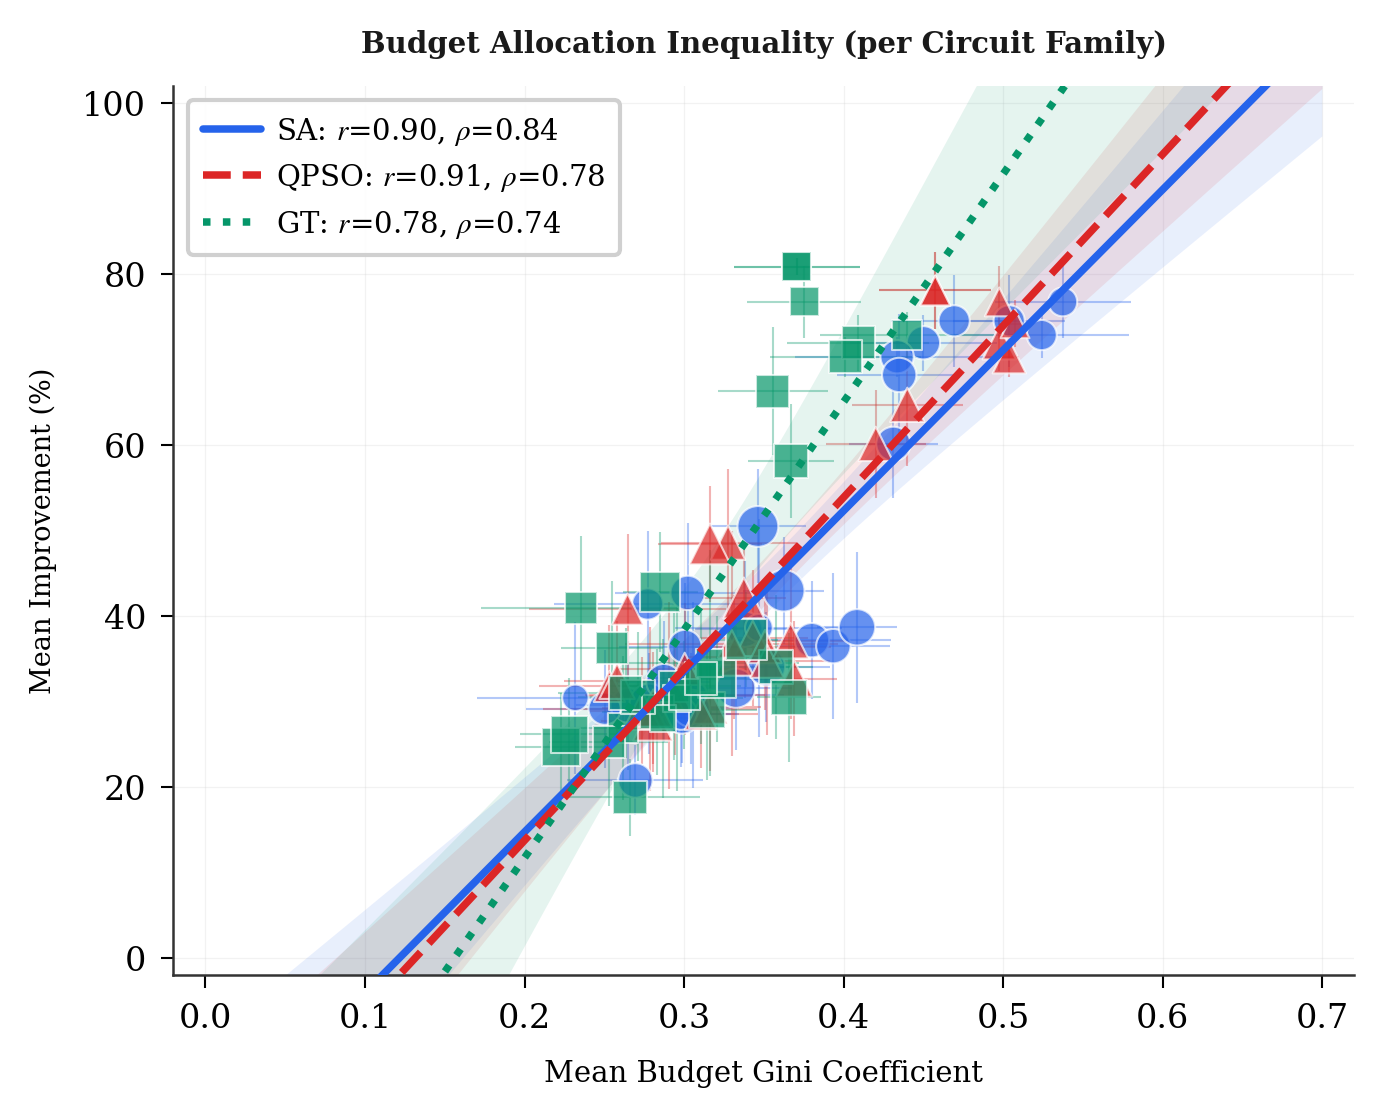


Figure 3 — Budget Gini Coefficient: SA vs QPSO vs GT
           (Per-benchmark aggregation, imp > 0)
  SA   (k=30 families):  Pearson r = +0.898 (p = 1.75e-11),  Spearman ρ = +0.843 (p = 4.94e-09),  R² = 0.806
  QPSO (k=30 families):  Pearson r = +0.912 (p = 2.50e-12),  Spearman ρ = +0.784 (p = 3.01e-07),  R² = 0.831
  GT   (k=30 families):  Pearson r = +0.782 (p = 3.31e-07),  Spearman ρ = +0.738 (p = 3.27e-06),  R² = 0.612


In [6]:
# FIGURE 3 — Budget Gini Coefficient Analysis  (SA vs QPSO vs GT)
#             Per-benchmark aggregation (circuit-family level)

def budget_gini(row):
    """Gini coefficient for a 3-component budget allocation."""
    vals = sorted([row['log_frac'], row['t_frac'], row['rot_frac']])
    n = 3
    numerator   = 2.0 * sum((i + 1) * v for i, v in enumerate(vals))
    denominator = n * sum(vals)
    if denominator == 0:
        return 0.0
    return numerator / denominator - (n + 1) / n

# Compute budget fractions and Gini for ALL THREE datasets
for df_cur in [df_sa, df_qpso, df_gt]:
    bsum = (df_cur['optimal_logical_budget'] +
            df_cur['optimal_t_states_budget'] +
            df_cur['optimal_rotations_budget'])
    bsum = bsum.replace(0, np.nan)
    df_cur['log_frac'] = df_cur['optimal_logical_budget'] / bsum
    df_cur['t_frac']   = df_cur['optimal_t_states_budget'] / bsum
    df_cur['rot_frac'] = df_cur['optimal_rotations_budget'] / bsum
    df_cur[['log_frac','t_frac','rot_frac']] = df_cur[['log_frac','t_frac','rot_frac']].fillna(1/3)
    df_cur['budget_gini'] = df_cur.apply(budget_gini, axis=1)

# Filter: only circuits where optimization produced improvement
df_sa_f   = df_sa[df_sa['metric_improvement_pct']   > 0].copy()
df_qpso_f = df_qpso[df_qpso['metric_improvement_pct'] > 0].copy()
df_gt_f   = df_gt[df_gt['metric_improvement_pct']   > 0].copy()

def _aggregate(df_f):
    return df_f.groupby('benchmark').agg(
        gini_mean=('budget_gini', 'mean'),
        imp_mean=('metric_improvement_pct', 'mean'),
        gini_std=('budget_gini', 'std'),
        imp_std=('metric_improvement_pct', 'std'),
        n=('metric_improvement_pct', 'count')
    ).dropna()

agg_sa   = _aggregate(df_sa_f)
agg_qpso = _aggregate(df_qpso_f)
agg_gt   = _aggregate(df_gt_f)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif', 'serif'],
    'mathtext.fontset': 'stix',
    'font.size': 8,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'axes.linewidth': 0.6,
    'axes.edgecolor': '#333333',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'ytick.right': False,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

fig, ax = plt.subplots(figsize=(4.8, 3.8))
fig.subplots_adjust(left=0.14, right=0.96, top=0.92, bottom=0.14)
ax.tick_params(axis='both', which='both', top=False, right=False)

x_fit_shared = np.linspace(0, 0.70, 200)

for agg, label, color, marker, ls in [
    (agg_sa,   LABEL_SA,   C_SA,   MARKER_SA,   '-'),
    (agg_qpso, LABEL_QPSO, C_QPSO, MARKER_QPSO, '--'),
    (agg_gt,   LABEL_GT,   C_GT,   MARKER_GT,   ':'),
]:
    x = agg['gini_mean'].values
    y = agg['imp_mean'].values

    r_val, p_val   = stats.pearsonr(x, y)
    rho_val, rho_p = spearmanr(x, y)

    slope, intercept, _, _, _ = stats.linregress(x, y)
    y_fit = slope * x_fit_shared + intercept

    n_      = len(x)
    x_mean  = np.mean(x)
    se_y    = np.sqrt(np.sum((y - (slope * x + intercept))**2) / (n_ - 2))
    ci      = stats.t.ppf(0.975, n_ - 2) * se_y * np.sqrt(
                1.0 / n_ + (x_fit_shared - x_mean)**2 / np.sum((x - x_mean)**2))

    x_err = agg['gini_std'].values / np.sqrt(agg['n'].values)
    y_err = agg['imp_std'].values  / np.sqrt(agg['n'].values)
    ax.errorbar(x, y, xerr=x_err, yerr=y_err,
                fmt='none', ecolor=color, elinewidth=0.5, alpha=0.35,
                capsize=0, zorder=1)

    sizes = 20 + agg['n'].values * 4
    ax.scatter(x, y, s=sizes, alpha=0.70, color=color,
               edgecolors='white', linewidths=0.5, rasterized=True,
               zorder=3, marker=marker)

    ax.fill_between(x_fit_shared, y_fit - ci, y_fit + ci,
                    color=color, alpha=0.10, zorder=1, linewidth=0)

    ax.plot(x_fit_shared, y_fit, color=color, linewidth=1.8, linestyle=ls,
            zorder=4, solid_capstyle='round',
            label=f'{label}: $r$={r_val:.2f}, $\\rho$={rho_val:.2f}')

ax.set_xlabel('Mean Budget Gini Coefficient', fontsize=7, labelpad=6)
ax.set_ylabel('Mean Improvement (%)', fontsize=6.5, labelpad=6)
ax.set_title('Budget Allocation Inequality (per Circuit Family)', fontsize=7,
             fontweight='semibold', color='#1a1a1a', pad=8)

ax.set_ylim(-2, 102)
ax.set_xlim(-0.02, 0.72)

ax.yaxis.grid(True, alpha=0.25, linewidth=0.3, color='#cccccc')
ax.xaxis.grid(True, alpha=0.25, linewidth=0.3, color='#cccccc')
ax.set_axisbelow(True)

ax.legend(fontsize=7, loc='upper left', framealpha=0.92,
          borderpad=0.5, handletextpad=0.5, handlelength=2.0,
          edgecolor='#cccccc')

plt.savefig('figures/fig3_gini_SA_vs_QPSO_vs_GT.pdf', bbox_inches='tight', pad_inches=0.03)
plt.savefig('figures/fig3_gini_SA_vs_QPSO_vs_GT.png', bbox_inches='tight', pad_inches=0.03, dpi=1200)
plt.show()

print("\n" + "="*78)
print("Figure 3 — Budget Gini Coefficient: SA vs QPSO vs GT")
print("           (Per-benchmark aggregation, imp > 0)")
print("="*78)
for agg, lbl in [(agg_sa, 'SA'), (agg_qpso, 'QPSO'), (agg_gt, 'GT')]:
    x = agg['gini_mean'].values
    y = agg['imp_mean'].values
    r, r_p = stats.pearsonr(x, y)
    rho, rho_p = spearmanr(x, y)
    print(f"  {lbl:<4} (k={len(agg):>2} families):  Pearson r = {r:+.3f} (p = {r_p:.2e}),  "
          f"Spearman ρ = {rho:+.3f} (p = {rho_p:.2e}),  R² = {r**2:.3f}")
print("="*78)

In [7]:
# FIGURE 3 — Budget Gini Coefficient Analysis  (SA vs QPSO)

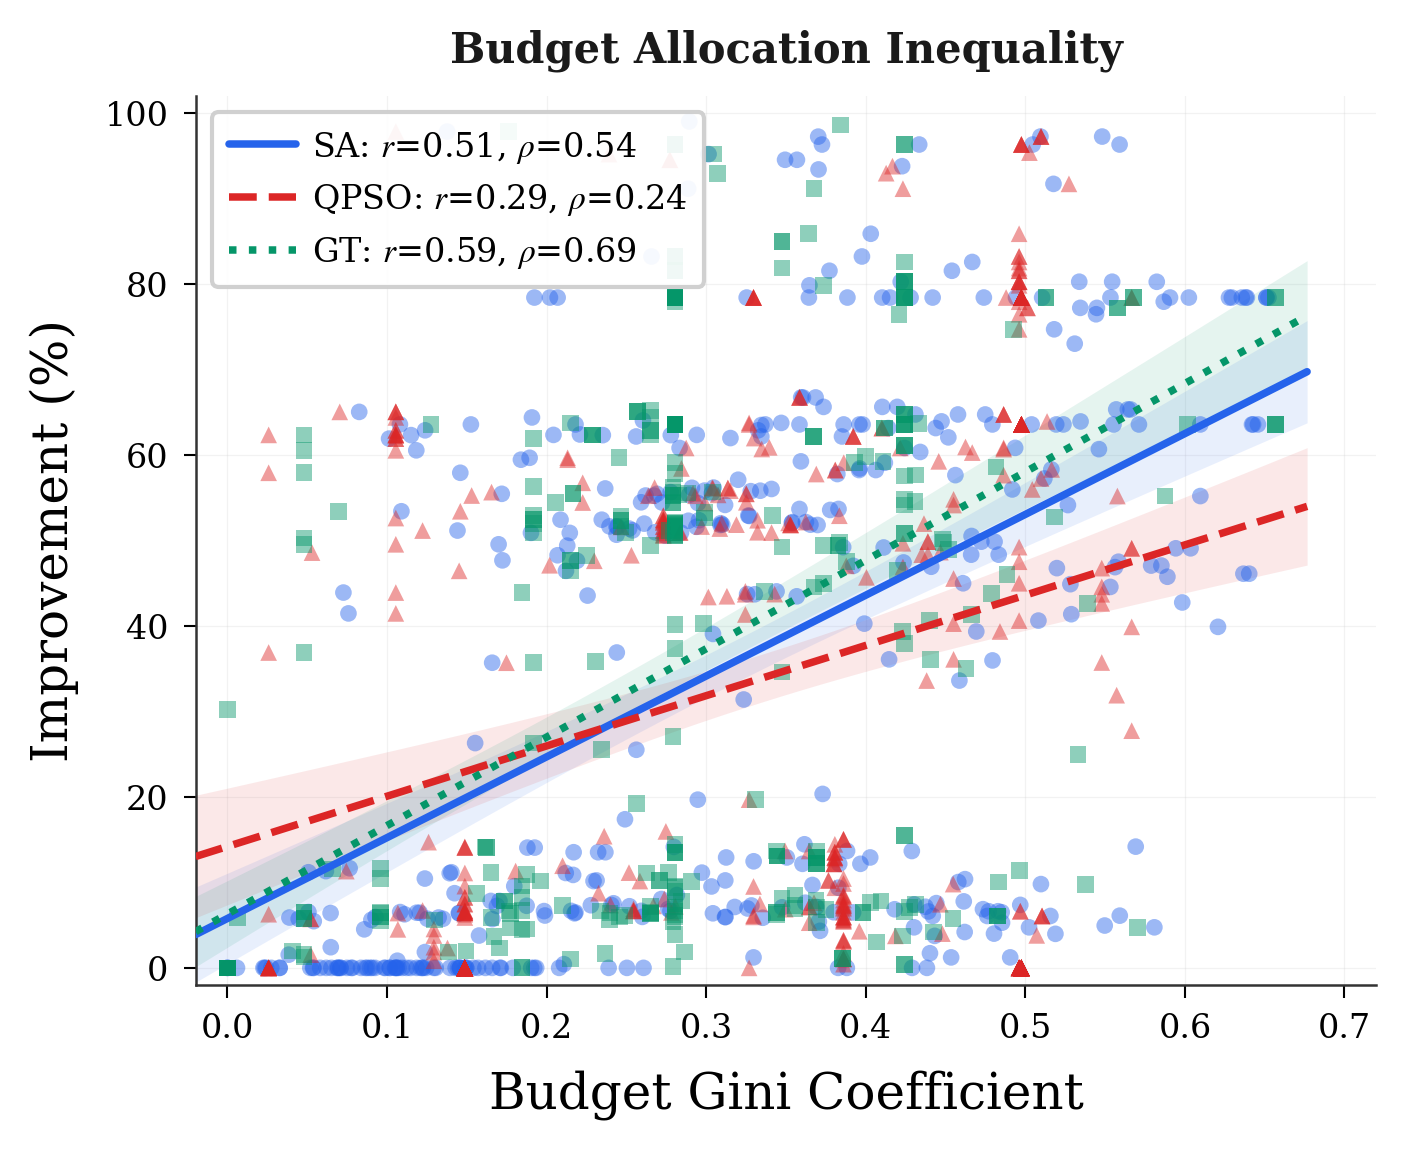


Figure 3 — Budget Gini Coefficient: SA vs QPSO vs GT (all samples)
  SA   (n= 433):  Pearson r = +0.513 (p = 1.74e-30),  Spearman ρ = +0.545 (p = 7.48e-35),  R² = 0.264
  QPSO (n= 433):  Pearson r = +0.288 (p = 9.58e-10),  Spearman ρ = +0.241 (p = 3.65e-07),  R² = 0.083
  GT   (n= 434):  Pearson r = +0.586 (p = 1.91e-41),  Spearman ρ = +0.692 (p = 3.99e-63),  R² = 0.344


In [8]:
# FIGURE 3 — Budget Gini Coefficient Analysis  (SA vs QPSO vs GT)
#             Per-sample, UNFILTERED (all samples)
# (Budget fractions + Gini already computed in the aggregated cell.)

plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'Times', 'DejaVu Serif', 'serif'],
    'mathtext.fontset': 'stix',
    'font.size': 8,
    'axes.labelsize': 9,
    'xtick.labelsize': 8,
    'ytick.labelsize': 8,
    'figure.dpi': 300,
    'savefig.dpi': 600,
    'axes.linewidth': 0.6,
    'axes.edgecolor': '#333333',
    'xtick.major.width': 0.5,
    'ytick.major.width': 0.5,
    'xtick.major.size': 3,
    'ytick.major.size': 3,
    'xtick.direction': 'out',
    'ytick.direction': 'out',
    'xtick.top': False,
    'ytick.right': False,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

fig, ax = plt.subplots(figsize=(4.8, 3.8))
fig.subplots_adjust(left=0.14, right=0.96, top=0.92, bottom=0.14)
ax.tick_params(axis='both', which='both', top=False, right=False)

global_gini_min = min(df_sa['budget_gini'].min(),
                      df_qpso['budget_gini'].min(),
                      df_gt['budget_gini'].min())
global_gini_max = max(df_sa['budget_gini'].max(),
                      df_qpso['budget_gini'].max(),
                      df_gt['budget_gini'].max())
x_fit_shared = np.linspace(global_gini_min - 0.02, global_gini_max + 0.02, 200)

for df_cur, label, color, marker, ls in [
    (df_sa,   LABEL_SA,   C_SA,   MARKER_SA,   '-'),
    (df_qpso, LABEL_QPSO, C_QPSO, MARKER_QPSO, '--'),
    (df_gt,   LABEL_GT,   C_GT,   MARKER_GT,   ':'),
]:
    x = df_cur['budget_gini'].values
    y = df_cur['metric_improvement_pct'].values

    r_val, p_val   = stats.pearsonr(x, y)
    rho_val, rho_p = spearmanr(x, y)

    slope, intercept, _, _, _ = stats.linregress(x, y)
    y_fit = slope * x_fit_shared + intercept

    n_      = len(x)
    x_mean  = np.mean(x)
    se_y    = np.sqrt(np.sum((y - (slope * x + intercept))**2) / (n_ - 2))
    ci      = stats.t.ppf(0.975, n_ - 2) * se_y * np.sqrt(
                1.0 / n_ + (x_fit_shared - x_mean)**2 / np.sum((x - x_mean)**2))

    ax.scatter(x, y, s=16, alpha=0.45, color=color,
               edgecolors='none', rasterized=True, zorder=2, marker=marker)

    ax.fill_between(x_fit_shared, y_fit - ci, y_fit + ci,
                    color=color, alpha=0.10, zorder=1, linewidth=0)

    ax.plot(x_fit_shared, y_fit, color=color, linewidth=1.8, linestyle=ls,
            zorder=4, solid_capstyle='round',
            label=f'{label}: $r$={r_val:.2f}, $\\rho$={rho_val:.2f}')

ax.set_xlabel('Budget Gini Coefficient', fontsize=12, labelpad=6)
ax.set_ylabel('Improvement (%)', fontsize=12, labelpad=6)
ax.set_title('Budget Allocation Inequality', fontsize=10,
             fontweight='semibold', color='#1a1a1a', pad=8)

ax.set_ylim(-2, 102)
ax.set_xlim(-0.02, 0.72)

ax.yaxis.grid(True, alpha=0.25, linewidth=0.3, color='#cccccc')
ax.xaxis.grid(True, alpha=0.25, linewidth=0.3, color='#cccccc')
ax.set_axisbelow(True)

ax.legend(fontsize=8, loc='upper left', framealpha=0.92,
          borderpad=0.5, handletextpad=0.5, handlelength=2.0,
          edgecolor='#cccccc')

plt.savefig('figures/fig3_gini_SA_vs_QPSO_vs_GT_all.pdf', bbox_inches='tight', pad_inches=0.03)
plt.savefig('figures/fig3_gini_SA_vs_QPSO_vs_GT_all.png', bbox_inches='tight', pad_inches=0.03, dpi=600)
plt.show()

print("\n" + "="*78)
print("Figure 3 — Budget Gini Coefficient: SA vs QPSO vs GT (all samples)")
print("="*78)
for df_cur, lbl in [(df_sa, 'SA'), (df_qpso, 'QPSO'), (df_gt, 'GT')]:
    x = df_cur['budget_gini'].values
    y = df_cur['metric_improvement_pct'].values
    r, r_p = stats.pearsonr(x, y)
    rho, rho_p = spearmanr(x, y)
    print(f"  {lbl:<4} (n={len(df_cur):>4}):  Pearson r = {r:+.3f} (p = {r_p:.2e}),  "
          f"Spearman ρ = {rho:+.3f} (p = {rho_p:.2e}),  R² = {r**2:.3f}")
print("="*78)